# Exploracao da base de YouTube Shorts

Notebook de leitura local: abre as coletas de **moda** e **automotivo**, sem API e sem chave. Execute todas as celulas em ordem.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "scripts").is_dir() and (p / "src").is_dir())
RUNS = {'moda': '20260924T163050Z', 'automotivo': '20260924T163415Z'}
MIN_SHORTS = 30
COLORS = {'moda': '#7b4f72', 'automotivo': '#28666e', 'brand': '#4c78a8', 'creator': '#f58518'}

eligible_parts, profile_parts = [], []
for sector, run_id in RUNS.items():
    folder = ROOT / 'data' / 'silver' / 'data_discovery' / run_id
    eligible_parts.append(pd.read_csv(folder / 'eligible_shorts.csv'))
    profile_parts.append(pd.read_csv(folder / 'channel_profile.csv'))

eligible = pd.concat(eligible_parts, ignore_index=True)
profiles = pd.concat(profile_parts, ignore_index=True)
eligible['published_at'] = pd.to_datetime(eligible['published_at'], utc=True)
eligible['like_count'] = pd.to_numeric(eligible['like_count'], errors='coerce')
approved = profiles.query('eligible_shorts >= @MIN_SHORTS').copy()
history = eligible.merge(approved[['channel_id']], on='channel_id', how='inner')

print(f'Shorts elegiveis: {len(eligible):,}')
print(f'Canais aprovados: {len(approved)}')
print(f'Shorts dos canais aprovados: {len(history):,}')

Shorts elegiveis: 2,464
Canais aprovados: 20
Shorts dos canais aprovados: 2,431


## 1. Quantidade por area

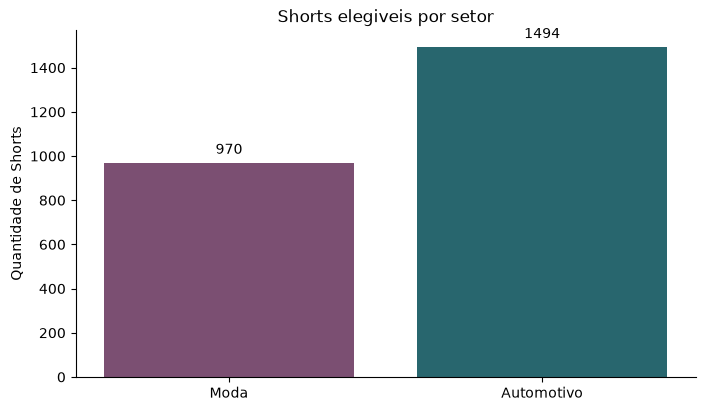

,sector,shorts_elegiveis
0,moda,970
1,automotivo,1494


In [2]:
by_sector = eligible.groupby('sector')['video_id'].nunique().reindex(['moda', 'automotivo'])
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(by_sector.index.str.title(), by_sector.values, color=[COLORS[x] for x in by_sector.index])
ax.bar_label(bars, padding=4)
ax.set_title('Shorts elegiveis por setor')
ax.set_ylabel('Quantidade de Shorts')
ax.spines[['top', 'right']].set_visible(False)
plt.show()
display(by_sector.rename('shorts_elegiveis').reset_index())

## 2. Quantidade de Shorts por canal

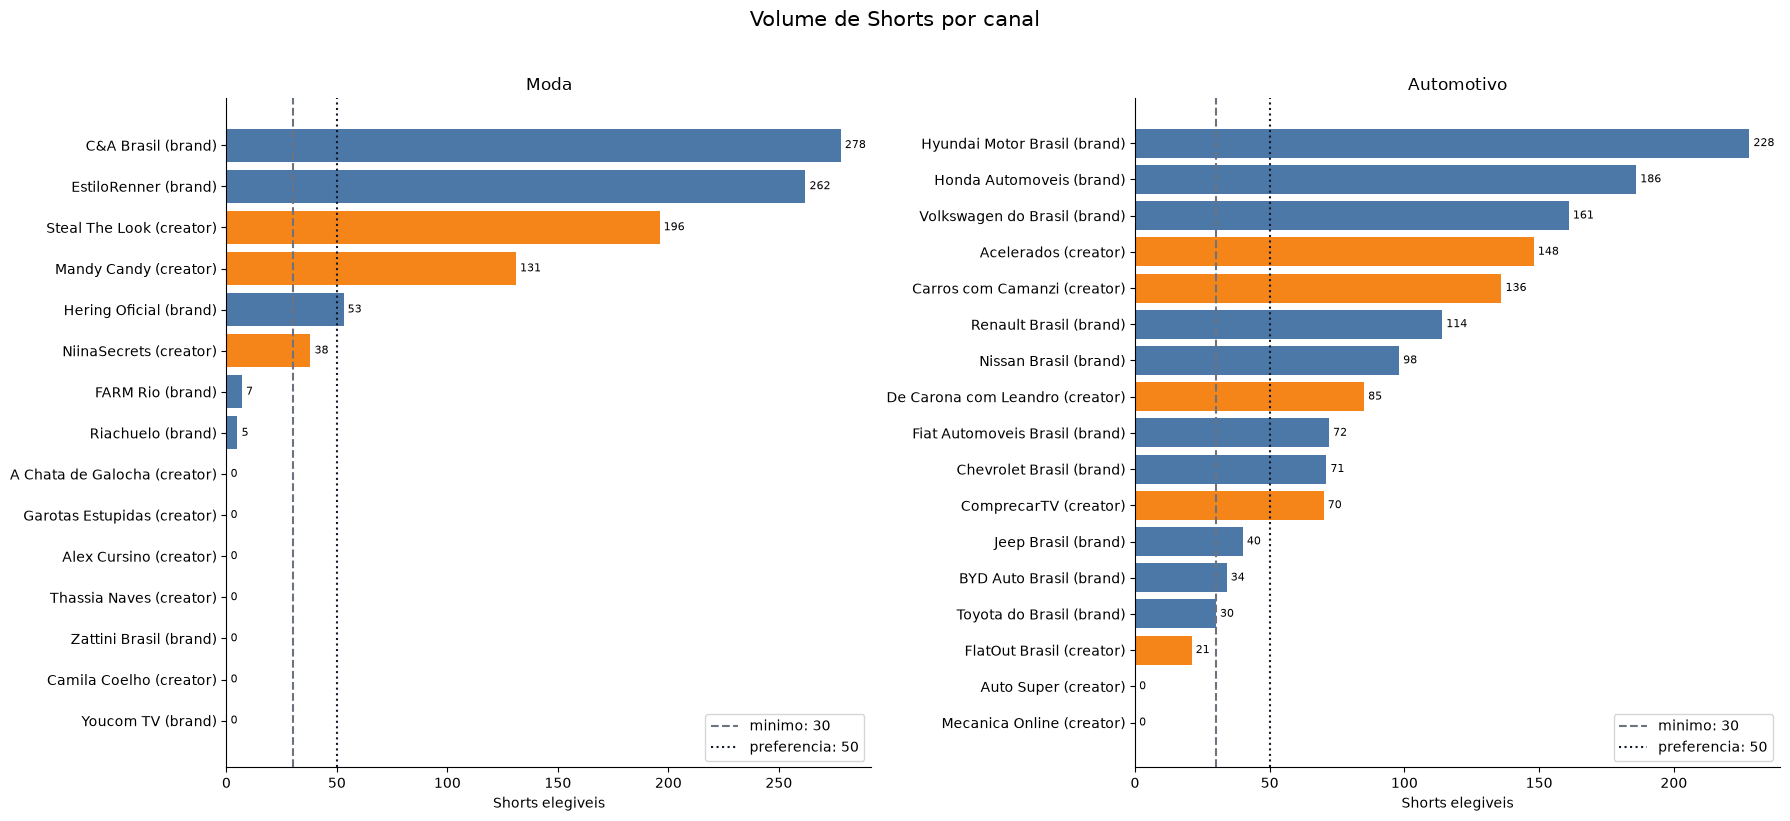

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, sector in zip(axes, ['moda', 'automotivo']):
    data = profiles.loc[profiles['sector'].eq(sector)].sort_values('eligible_shorts')
    labels = data['channel_name'] + ' (' + data['channel_type'] + ')'
    bars = ax.barh(labels, data['eligible_shorts'], color=data['channel_type'].map(COLORS))
    ax.bar_label(bars, padding=3, fontsize=8)
    ax.axvline(30, color='#6b7280', linestyle='--', label='minimo: 30')
    ax.axvline(50, color='#111827', linestyle=':', label='preferencia: 50')
    ax.set_title(sector.title())
    ax.set_xlabel('Shorts elegiveis')
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='lower right')
fig.suptitle('Volume de Shorts por canal', y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

## 3. Historico de curtidas e validade da variacao

Cada ponto e um Short. A escala de curtidas e logaritmica para comparar canais de tamanhos diferentes. A linha tracejada e a mediana do canal.

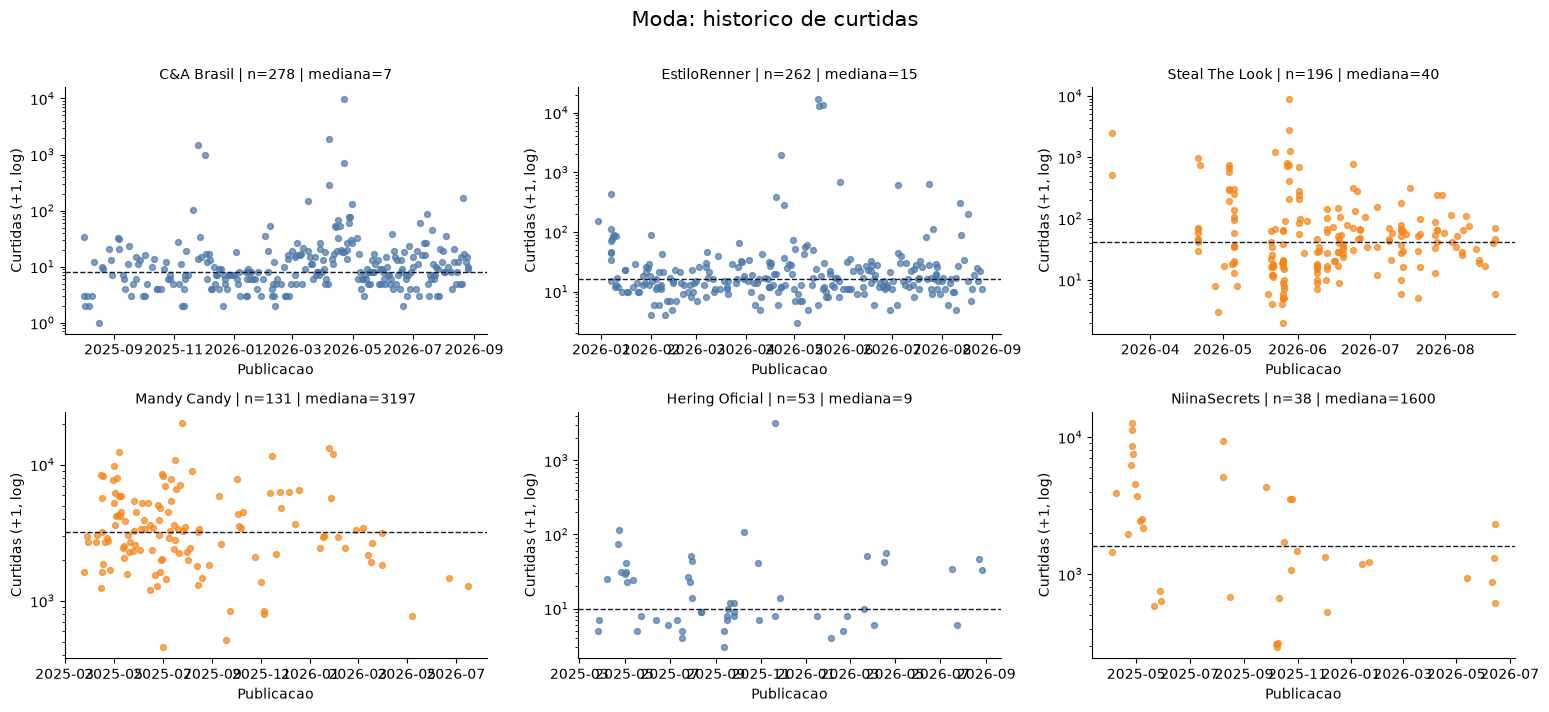

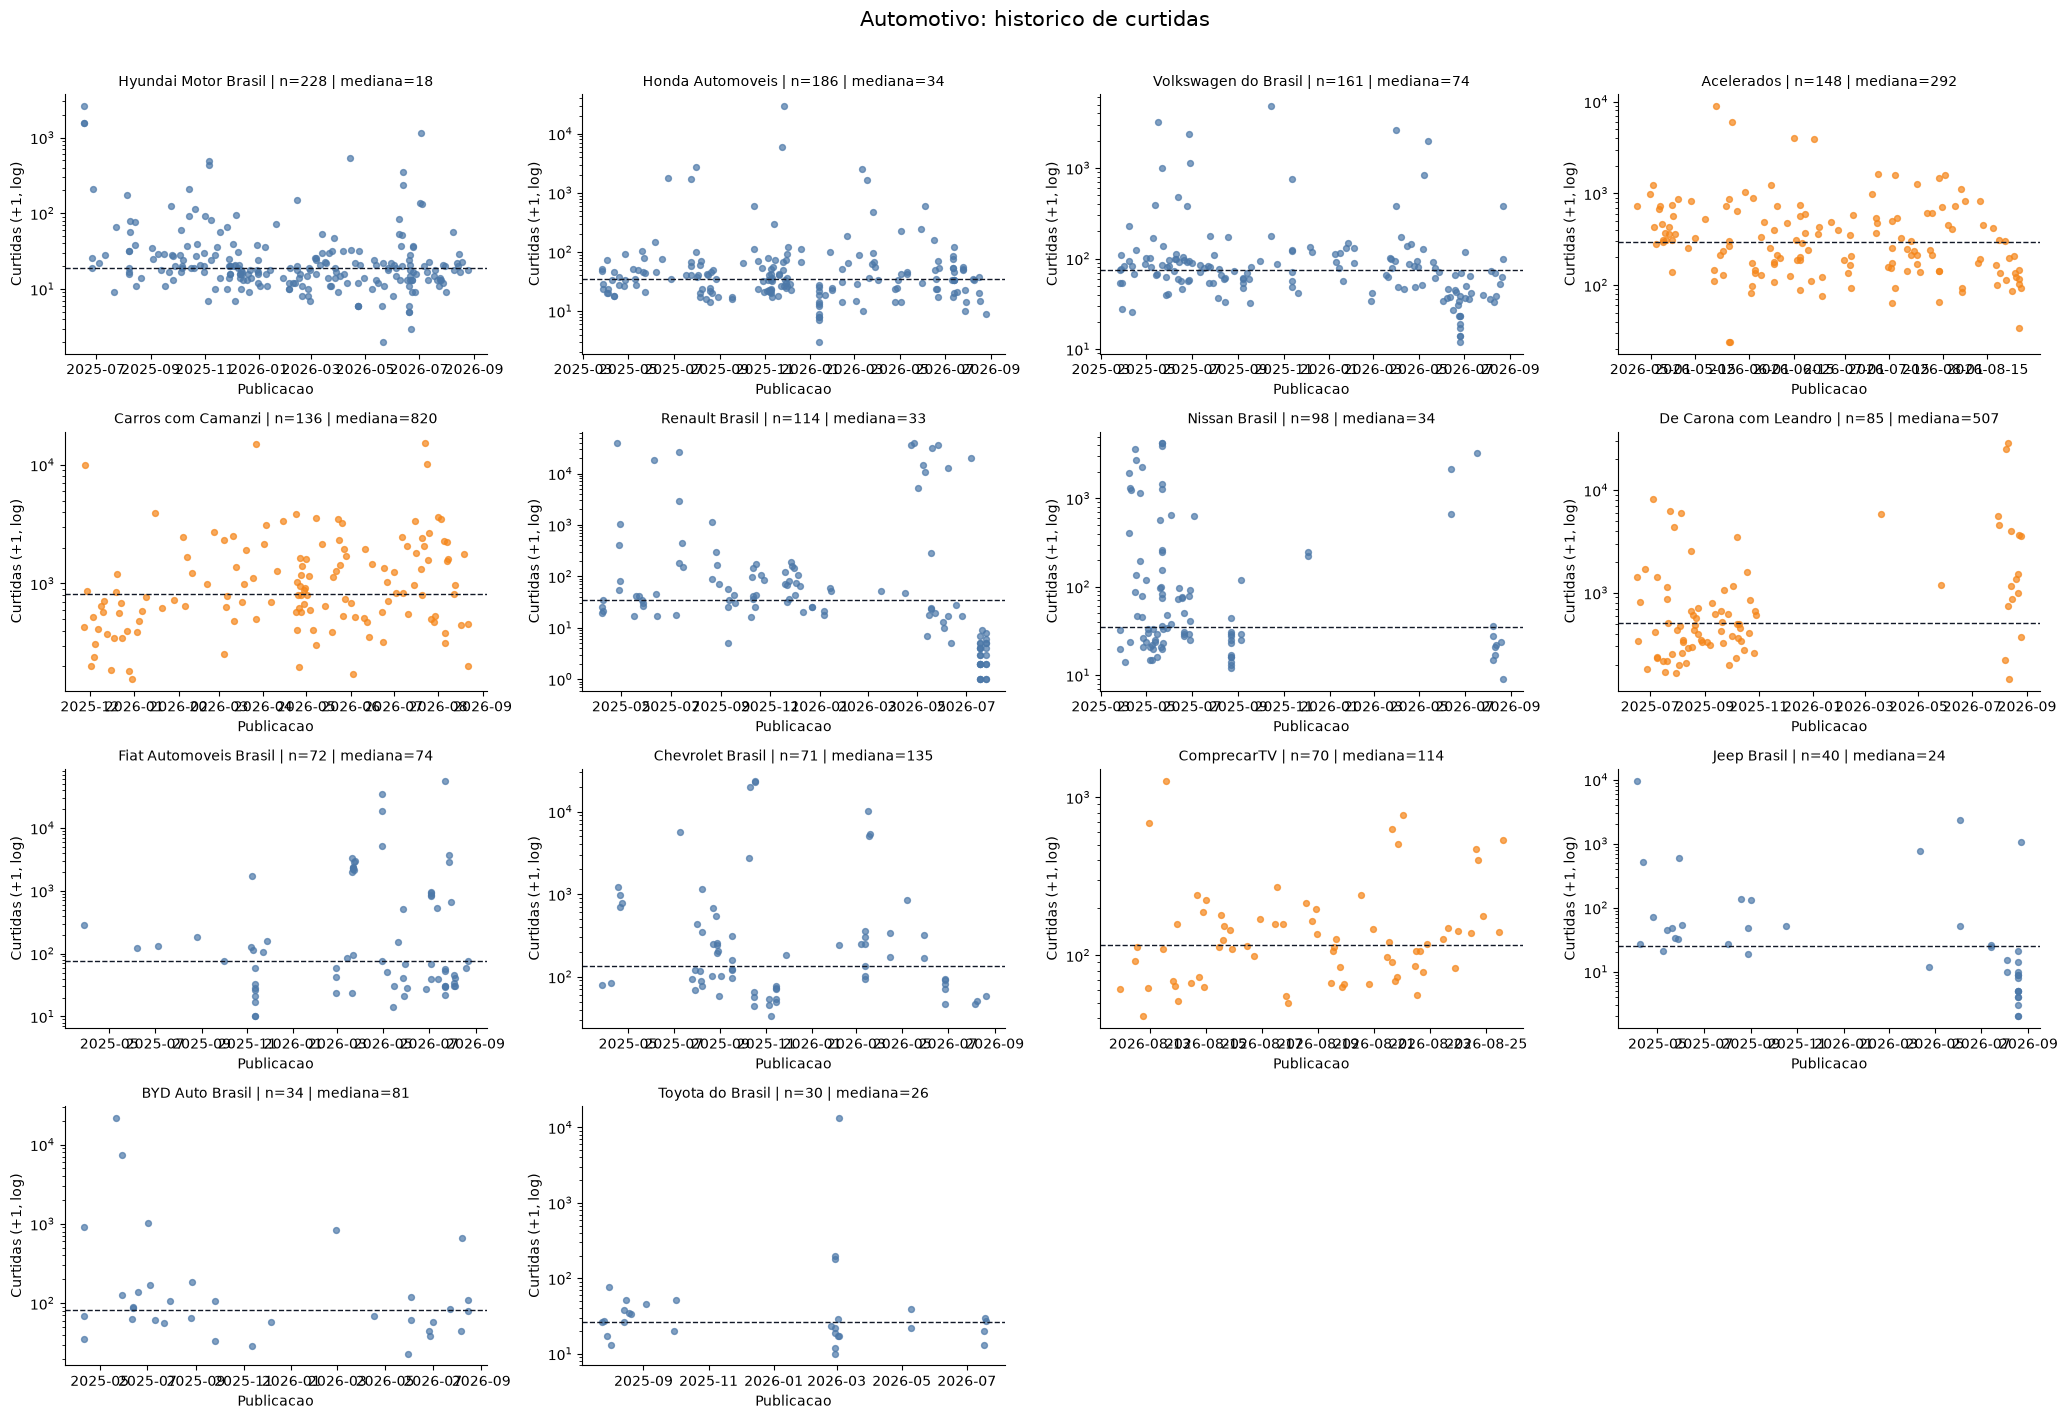

In [4]:
def plot_history(sector, columns):
    channels = approved.loc[approved['sector'].eq(sector)].sort_values('eligible_shorts', ascending=False)
    rows = -(-len(channels) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(5.2 * columns, 3.5 * rows), squeeze=False)
    for ax, (_, channel) in zip(axes.ravel(), channels.iterrows()):
        data = history.loc[history['channel_id'].eq(channel['channel_id'])].sort_values('published_at')
        median = data['like_count'].median()
        ax.scatter(data['published_at'], data['like_count'] + 1, s=18, alpha=.7, color=COLORS[channel['channel_type']])
        ax.axhline(median + 1, color='#111827', linestyle='--', linewidth=1)
        ax.set_yscale('log')
        ax.set_title(f"{channel['channel_name']} | n={len(data)} | mediana={median:.0f}", fontsize=10)
        ax.set_xlabel('Publicacao')
        ax.set_ylabel('Curtidas (+1, log)')
        ax.spines[['top', 'right']].set_visible(False)
    for ax in axes.ravel()[len(channels):]: ax.set_visible(False)
    fig.suptitle(f'{sector.title()}: historico de curtidas', y=1.01, fontsize=15)
    plt.tight_layout()
    plt.show()

plot_history('moda', 3)
plot_history('automotivo', 4)

In [5]:
validity = (
    history.groupby(['sector', 'channel_name', 'channel_type'])
    .agg(shorts=('video_id', 'nunique'), inicio=('published_at', 'min'), fim=('published_at', 'max'), curtidas_unicas=('like_count', 'nunique'), mediana=('like_count', 'median'), iqr=('like_count', lambda x: x.quantile(.75) - x.quantile(.25)), minimo=('like_count', 'min'), maximo=('like_count', 'max'))
    .reset_index()
)
validity['dias_cobertos'] = (validity['fim'] - validity['inicio']).dt.days
validity['variacao_observavel'] = validity['curtidas_unicas'].ge(10) & validity['iqr'].gt(0) & validity['dias_cobertos'].ge(90)
display(validity.sort_values(['sector', 'shorts'], ascending=[True, False]))
print(f"Canais com variacao observavel: {validity['variacao_observavel'].sum()} de {len(validity)}")

,sector,channel_name,channel_type,shorts,inicio,fim,curtidas_unicas,mediana,iqr,minimo,maximo,dias_cobertos,variacao_observavel
8,automotivo,Hyundai Motor Brasil,brand,228,2025-06-17 14:37:03+00:00,2026-08-24 21:00:14+00:00,67,18.0,16.00,1.0,2594.0,433,True
7,automotivo,Honda Automoveis,brand,186,2025-03-26 00:50:31+00:00,2026-08-24 19:49:04+00:00,88,34.0,33.75,2.0,29294.0,516,True
13,automotivo,Volkswagen do Brasil,brand,161,2025-03-25 19:01:40+00:00,2026-08-22 20:48:31+00:00,103,74.0,53.00,11.0,4807.0,515,True
0,automotivo,Acelerados,creator,148,2026-04-26 18:21:12+00:00,2026-08-25 15:29:11+00:00,138,292.5,398.25,23.0,8923.0,120,True
2,automotivo,Carros com Camanzi,creator,136,2025-11-26 18:32:44+00:00,2026-08-21 15:01:44+00:00,132,820.0,1163.50,155.0,15162.0,267,True
11,automotivo,Renault Brasil,brand,114,2025-04-06 15:25:57+00:00,2026-07-24 20:32:21+00:00,76,33.0,97.50,0.0,38540.0,474,True
10,automotivo,Nissan Brasil,brand,98,2025-03-25 22:18:55+00:00,2026-08-21 18:55:08+00:00,65,34.0,126.50,8.0,4180.0,513,True
5,automotivo,De Carona com Leandro,creator,85,2025-06-16 11:50:04+00:00,2026-08-25 12:30:55+00:00,84,507.0,836.00,143.0,28468.0,435,True
6,automotivo,Fiat Automoveis Brasil,brand,72,2025-03-28 00:14:25+00:00,2026-08-21 14:26:05+00:00,60,74.0,834.50,9.0,56533.0,511,True
3,automotivo,Chevrolet Brasil,brand,71,2025-03-26 21:04:33+00:00,2026-08-19 21:07:56+00:00,66,135.0,275.00,32.0,23695.0,511,True


Canais com variacao observavel: 19 de 20
